# Beat 6: Equivalência — Grad-CAM é um CAM generalizado?

**Pergunta:** o Grad-CAM é mesmo um CAM generalizado?

**Tempo:** 3 min. Depende da Fase 5 (`gradcam.cam`, `scripts/05_cam_vs_gradcam.py`).
O CAM original exige `conv → GAP → fc` e perde acurácia; o Grad-CAM não exige
nada disso. A §3.1 do paper mostra que, quando o CAM é aplicável, os dois são o
**mesmo mapa** a menos de uma constante.

In [1]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import torch
import matplotlib.pyplot as plt
from PIL import Image

from gradcam import cam, gradcam, resolve_cam_layers
from gradcam.metrics import spearman
from gradcam.models import denormalize, imagenet_labels, load_model, preprocess
from gradcam.viz import figure_grid, overlay, tensor_to_numpy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model("resnet18", device=device)
labels = imagenet_labels()
print(f"ResNet-18 carregado em {device}")

ResNet-18 carregado em cpu


## A derivação, em duas linhas

Em `conv → GAP → fc`, o score da classe é `y^c = Σ_k w_k^c · (1/Z) Σ_ij A_ij^k`.
Logo `∂y^c/∂A_ij^k = w_k^c / Z` e a média espacial de (1) não depende de `i,j`:

```
α_k^c = (1/Z) Σ_ij ∂y^c/∂A_ij^k = w_k^c / Z
L_CAM^c = ReLU( Σ_k w_k^c A^k ) = ReLU( Σ_k Z·α_k^c A^k ) = Z · L_GradCAM^c
```

Ou seja: mesmos pesos, mesma camada, mesmo mapa — a menos de `Z = H·W`. A célula
abaixo verifica isso numericamente, com **a mesma camada** nos dois métodos.

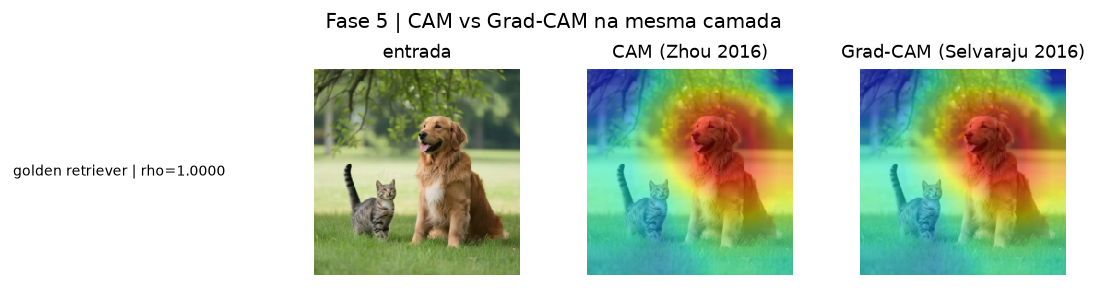

classe: golden retriever | camada: Sequential
Z = H*W = 49 | mapa (7, 7)
Spearman(CAM, Z*Grad-CAM) = 1.000000
max|Z*Grad-CAM - CAM| = 3.81e-06


In [2]:
base = "notebooks/assets" if os.path.isdir("notebooks/assets") else "assets"
image = Image.open(os.path.join(base, "cat_dog.jpg")).convert("RGB")
x = preprocess(image)
image_rgb = tensor_to_numpy(denormalize(x))

# A camada é resolvida uma vez e passada aos dois métodos. Sem isso, o CAM usa
# a saída do bloco (pós-ReLU) e o Grad-CAM cai no último Conv2d (pré-BatchNorm):
# a comparação mede a diferença entre camadas, não a equivalência de §3.1.
layer, fc = resolve_cam_layers(model)
class_idx = int(model(x).argmax(dim=1).item())

cam_map, _ = cam(model, x, class_idx=class_idx, layer=layer)
gc_map, _ = gradcam(model, x, class_idx=class_idx, layer=layer)
# Os mapas saem do autograd com grad_fn; para medir e plotar, solta o grafo.
cam_map, gc_map = cam_map.detach(), gc_map.detach()
Z = cam_map.numel()

rho = spearman(cam_map, gc_map)
max_diff = (Z * gc_map - cam_map).abs().max().item()

fig = figure_grid(
    [[
        image_rgb,
        overlay(image_rgb, cam_map, high=0.99, gamma=0.5),
        overlay(image_rgb, gc_map, high=0.99, gamma=0.5),
    ]],
    col_titles=("entrada", "CAM (Zhou 2016)", "Grad-CAM (Selvaraju 2016)"),
    row_titles=[f"{labels[class_idx]} | rho={rho:.4f}"],
    suptitle="Fase 5 | CAM vs Grad-CAM na mesma camada",
)
plt.show()

print(f"classe: {labels[class_idx]} | camada: {layer.__class__.__name__}")
print(f"Z = H*W = {Z} | mapa {tuple(cam_map.shape)}")
print(f"Spearman(CAM, Z*Grad-CAM) = {rho:.6f}")
print(f"max|Z*Grad-CAM - CAM| = {max_diff:.2e}")

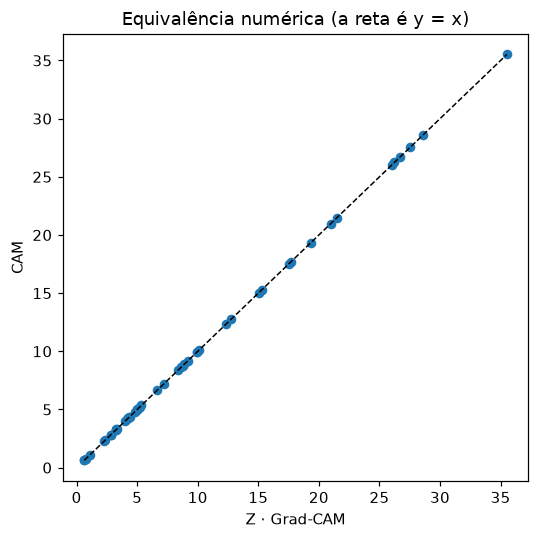

In [3]:
plt.figure(figsize=(5, 5), dpi=110)
plt.scatter(
    (Z * gc_map).detach().flatten().cpu().numpy(),
    cam_map.detach().flatten().cpu().numpy(),
    s=28,
)
low = float(min((Z * gc_map).min(), cam_map.min()))
high = float(max((Z * gc_map).max(), cam_map.max()))
plt.plot([low, high], [low, high], "--", color="black", linewidth=1)
plt.xlabel("Z · Grad-CAM")
plt.ylabel("CAM")
plt.title("Equivalência numérica (a reta é y = x)")
plt.tight_layout()
plt.show()

**Os pontos caem na reta `y = x`.** É a prova da §3.1 na prática: o Grad-CAM não
é uma heurística parecida com o CAM, é o CAM generalizado — vale em rede sem GAP
e sem retreinar, e no ResNet-18 reproduz o CAM a menos de `Z`.

O número canônico do repositório está em `results/metrics/cam_vs_gradcam.json`
(imagem do COCO val2017). A célula ao lado lê o JSON; o `cat_dog.jpg` acima é só
para rodar sem `data/`.

In [4]:
import json

metrics_path = os.path.join("results", "metrics", "cam_vs_gradcam.json")
if not os.path.exists(metrics_path):
    metrics_path = os.path.join("..", "results", "metrics", "cam_vs_gradcam.json")

with open(metrics_path, "r", encoding="utf-8") as handle:
    measured = json.load(handle)

print(
    f"JSON: imagem {measured['image']} | {measured['class_name']} | "
    f"camada {measured.get('layer') or 'layer4 (ResNet18)'} | "
    f"Z={measured['Z']}"
)
print(
    f"rho = {measured['spearman']:.6f} | "
    f"max|Z*Grad-CAM - CAM| = {measured['max_abs_diff']:.2e}"
)
print(f"fonte: {metrics_path} (script 05_cam_vs_gradcam.py)")

JSON: imagem 61333 | bookcase | camada layer4 (ResNet18) | Z=49
rho = 1.000000 | max|Z*Grad-CAM - CAM| = 5.72e-06
fonte: ..\results\metrics\cam_vs_gradcam.json (script 05_cam_vs_gradcam.py)


**Takeaway:** o CAM é um caso particular do Grad-CAM, não um método rival. A
generalização custou uma linha de gradiente — e é o que permite explicar VGG,
ResNet, qualquer arquitetura com camada convolucional.

Fonte dos números: `results/metrics/cam_vs_gradcam.json` (nenhum valor digitado à
mão). Linha do README: status da Fase 5 e a seção de medições.